# Lab 2: Exploratory Analysis of Public Transport Data
## 1) Data Analysis

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

DATA_PATH = Path("data") / "all_data_with_station_2_month.csv"
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

UTC_OFFSET_H = 2    #local time = UTC + 2
OPDAY_START_HOUR = 3    #the operating day is displayed from 03:00 local; hours 00-02 are labelled (+1d)

# Inclusive operating-date split (EXPLOIT_DATE)
SPLITS = {
    "train": ("2021-04-01", "2021-04-25"),
    "val":   ("2021-04-26", "2021-05-10"),
    "test":  ("2021-05-11", "2021-05-24"),
}

VOIES = [1, 2]
VOIE_COLORS = {1: "tab:blue", 2: "tab:orange"}
DAYTYPE_COLORS = {"weekday": "tab:blue", "weekend": "tab:red"}
WEEKDAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

### Loading the data

In [ ]:
# Code provided
df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH} -> shape = {df_raw.shape}")
print(df_raw.head())

Loaded data/all_data_with_station_2_month.csv -> shape = (688843, 10)
         DATE     HEURE  VOIE                  TIMESTAMP  PASSENGER  ID_MIS  DELTA_PASSENGER  NUM_VAL EXPLOIT_DATE  \
0  01/04/2021  05:13:36     1  2021-04-01 03:13:36+00:00          6       1                6       10   2021-04-01   
1  01/04/2021  05:21:01     2  2021-04-01 03:21:01+00:00         15       2               15       18   2021-04-01   
2  01/04/2021  05:30:17     1  2021-04-01 03:30:17+00:00         24       6               24       25   2021-04-01   
3  01/04/2021  05:30:54     1  2021-04-01 03:30:54+00:00         14       8               14        0   2021-04-01   
4  01/04/2021  05:31:18     2  2021-04-01 03:31:18+00:00         10       9               10       25   2021-04-01   

   STATION  
0        4  
1        4  
2        1  
3        1  
4        1  


In [ ]:
def load_records(path, count_col="PASSENGER"):
    # Keep only the useful fields, with standard names. NUM_VAL is not added to the count.
    raw = pd.read_csv(path, usecols=["HEURE", "VOIE", "EXPLOIT_DATE", "STATION", count_col])
    return pd.DataFrame({
        "op_date": pd.to_datetime(raw["EXPLOIT_DATE"]),     #operating day
        "station": pd.to_numeric(raw["STATION"]).round().astype(int),
        "voie": raw["VOIE"].astype(int),
        "hour": raw["HEURE"].str.slice(0, 2).astype(int),   #local hourly interval [h, h+1)
        "count": raw[count_col].astype(float),
    })


records = load_records(DATA_PATH)

# Checks: local time = UTC + 2, and records after midnight keep the operating date of EXPLOIT_DATE
ts_local_hour = (pd.to_datetime(df_raw["TIMESTAMP"]) + pd.Timedelta(hours=UTC_OFFSET_H)).dt.hour
print("HEURE consistent with TIMESTAMP + 2h:", (ts_local_hour == df_raw["HEURE"].str[:2].astype(int)).all())
print("Records whose calendar DATE differs from EXPLOIT_DATE (after local midnight):",
      (pd.to_datetime(df_raw["DATE"], dayfirst=True) != pd.to_datetime(df_raw["EXPLOIT_DATE"])).sum())
print("Observed zero counts in raw records:", (records["count"] == 0).sum())

HEURE consistent with TIMESTAMP + 2h: True
Records whose calendar DATE differs from EXPLOIT_DATE (after local midnight): 14842
Observed zero counts in raw records: 51


### Hourly counts per operating day

Within each operating day (`EXPLOIT_DATE`), `PASSENGER` is summed by station, direction and local hourly interval.
The result is stored on a full grid (every date of the period × station × direction × operating hour) so that
an interval without any record stays `NaN` instead of 0, while observed
zeros are kept. Hours are ordered by operating day: 04:00 … 23:00, 00:00 (+1d), 01:00 (+1d), 02:00 (+1d).

In [ ]:
def opday_position(hours):
    # Position of a local hour in the operating day (0 = OPDAY_START_HOUR)
    return (np.asarray(hours) - OPDAY_START_HOUR) % 24


def hour_label(h):
    h = int(h)
    return f"{h:02d}:00" + (" (+1d)" if h < OPDAY_START_HOUR else "")


def operating_hours(hours):
    # Contiguous list of local hours, in operating-day order, covering all recorded hours
    pos = opday_position(pd.unique(np.asarray(hours)))
    return [int((OPDAY_START_HOUR + p) % 24) for p in range(pos.min(), pos.max() + 1)]


def set_hour_axis(ax, hours, axis="x"):
    # Axis positions 0..len(hours)-1 labelled with operating-day hours
    labels = [hour_label(h) for h in hours]
    if axis == "x":
        ax.set_xticks(range(len(hours)), labels, rotation=90)
        ax.set_xlim(-0.5, len(hours) - 0.5)
    else:
        ax.set_yticks(range(len(hours)), labels)


def build_hourly_counts(records):
    # Series indexed (op_date, station, voie, hour) on the full grid; NaN = no record
    sums = records.groupby(["op_date", "station", "voie", "hour"])["count"].sum()
    dates = pd.date_range(records["op_date"].min(), records["op_date"].max(), freq="D")
    stations = sorted(records["station"].unique())
    voies = sorted(records["voie"].unique())
    hours = operating_hours(records["hour"])
    grid = pd.MultiIndex.from_product([dates, stations, voies, hours],
                                      names=["op_date", "station", "voie", "hour"])
    return sums.reindex(grid).rename("count")


def select(hourly, dates=None, stations=None, voies=None, hours=None):
    # Subset the hourly grid (None = keep everything)
    idx = hourly.index
    mask = np.ones(len(hourly), dtype=bool)
    for level, values in [("op_date", dates), ("station", stations), ("voie", voies), ("hour", hours)]:
        if values is not None:
            mask &= idx.get_level_values(level).isin(values)
    return hourly[mask]


hourly_all = build_hourly_counts(records)
DATES_ALL = hourly_all.index.levels[0]
STATIONS = list(hourly_all.index.levels[1])
HOURS = list(pd.unique(hourly_all.index.get_level_values("hour")))   #operating-day order

print("Operating hours:", [hour_label(h) for h in HOURS])
print("Period:", DATES_ALL[0].date(), "->", DATES_ALL[-1].date(), f"({len(DATES_ALL)} days),", len(STATIONS), "stations")
missing_dates = DATES_ALL.difference(pd.DatetimeIndex(records["op_date"].unique()))
print("Operating dates without any record:", [f"{d:%a %d %b}" for d in missing_dates])
print("\nRecords per local hour:")
print(records.groupby("hour").size().reindex(HOURS).rename(index=hour_label).to_frame("n_records").T)

Operating hours: ['04:00', '05:00', '06:00', '07:00', '08:00', '09:00', '10:00', '11:00', '12:00', '13:00', '14:00', '15:00', '16:00', '17:00', '18:00', '19:00', '20:00', '21:00', '22:00', '23:00', '00:00 (+1d)', '01:00 (+1d)', '02:00 (+1d)']
Period: 2021-04-01 -> 2021-05-24 (54 days), 24 stations
Operating dates without any record: ['Wed 07 Apr', 'Tue 20 Apr', 'Fri 30 Apr']

Records per local hour:
hour       04:00  05:00  06:00  07:00  08:00  09:00  10:00  11:00  12:00  13:00  14:00  15:00  16:00  17:00  18:00  \
n_records      3   7069  26791  42960  53135  49195  37909  35099  35047  34783  36014  38944  47068  52664  52695   

hour       19:00  20:00  21:00  22:00  23:00  00:00 (+1d)  01:00 (+1d)  02:00 (+1d)  
n_records  46412  29310  17627  15620  15656        13505         1335            2  


### Date split, weekdays and weekends

Section 1 uses the training dates only (1–25 April). Weekdays = Monday–Friday, weekends = Saturday–Sunday,
based on the operating date.

In [5]:
def split_dates(name):
    start, end = SPLITS[name]
    return pd.date_range(start, end, freq="D")


def assign_split(dates):
    dates = pd.DatetimeIndex(dates)
    out = pd.Series(pd.NA, index=dates, dtype="object", name="split")
    for name, (start, end) in SPLITS.items():
        out[(dates >= start) & (dates <= end)] = name
    return out


def day_type(dates):
    return np.where(pd.DatetimeIndex(dates).dayofweek >= 5, "weekend", "weekday")


def dates_of_type(dates, kind):
    dates = pd.DatetimeIndex(dates)
    return dates[day_type(dates) == kind]


TRAIN_DATES, VAL_DATES, TEST_DATES = split_dates("train"), split_dates("val"), split_dates("test")
hourly_train = select(hourly_all, dates=TRAIN_DATES)

print(assign_split(DATES_ALL).value_counts().to_string())
print("Training weekdays / weekend days:", len(dates_of_type(TRAIN_DATES, "weekday")),
      "/", len(dates_of_type(TRAIN_DATES, "weekend")))

split
train    25
val      15
test     14
Training weekdays / weekend days: 17 / 8


### Missing intervals and incomplete totals

The first hours (04:00–05:00) and last hours (01:00–02:00 (+1d)) are recorded only by some stations, on some days,
and only in the first/last minutes of the hour: they correspond to the first and last runs of service, so their
absence most likely reflects the timetable, not lost data. We therefore call a `(station, direction, hour)` cell
expected when that station/direction records that hour on at least 95 % of its active training days.
A total (network-wide hourly or daily) is flagged as incomplete when at least one expected cell is missing.
Incomplete totals are still displayed but marked, and are excluded from the day-of-week distributions.

In [6]:
REGULAR_HOUR_MIN_SHARE = 0.95


def regular_hours_table(hourly, min_share=REGULAR_HOUR_MIN_SHARE):
    # (station, voie) x hour -> True if the hour is recorded on >= min_share of the station's active days
    obs = hourly.notna().unstack("hour")
    active = obs.any(axis=1)
    return obs[active].groupby(level=["station", "voie"]).mean() >= min_share


def expected_mask(hourly, regular):
    # Is each cell of the hourly grid an expected (regularly recorded) cell?
    key = pd.MultiIndex.from_arrays([hourly.index.get_level_values(l) for l in ["station", "voie", "hour"]])
    return regular.stack().reindex(key).fillna(False).to_numpy(dtype=bool)


def station_day_completeness(hourly, regular):
    # One row per (op_date, station, voie): number of observed / expected / missing expected hours
    df = pd.DataFrame({"observed": hourly.notna().to_numpy(),
                       "expected": expected_mask(hourly, regular)}, index=hourly.index)
    df["missing_expected"] = df["expected"] & ~df["observed"]
    out = df.groupby(level=["op_date", "station", "voie"]).sum()
    out["complete"] = out["missing_expected"] == 0
    return out


regular_train = regular_hours_table(hourly_train)
print("Number of stations regularly recording each hour:")
print(regular_train.groupby(level="voie").sum().reindex(columns=HOURS).rename(columns=hour_label))

completeness_all = station_day_completeness(hourly_all, regular_train)
incomplete = completeness_all[~completeness_all["complete"]].reset_index()
incomplete["split"] = assign_split(incomplete["op_date"]).to_numpy()
print("\nIncomplete station-days (missing expected hours), whole period:")
print(incomplete.groupby(["split", "op_date", "voie"])
      .apply(lambda d: "no record at all" if d.name[1] in missing_dates
             else ", ".join(f"S{s}({m})" for s, m in zip(d.station, d.missing_expected)), include_groups=False)
      .rename("station(n_missing_hours)").to_string())

Number of stations regularly recording each hour:
hour  04:00  05:00  06:00  07:00  08:00  09:00  10:00  11:00  12:00  13:00  14:00  15:00  16:00  17:00  18:00  19:00  \
voie                                                                                                                   
1         0     24     24     24     24     24     24     24     24     24     24     24     24     24     24     24   
2         0     16     24     24     24     24     24     24     24     24     24     24     24     24     24     24   

hour  20:00  21:00  22:00  23:00  00:00 (+1d)  01:00 (+1d)  02:00 (+1d)  
voie                                                                     
1        24     24     24     24           24            1            0  
2        24     23     23     23           24           13            0  

Incomplete station-days (missing expected hours), whole period:
split  op_date     voie
test   2021-05-17  1                                             S17(17)
           

## 1.1 Examine network-wide demand

The hourly counts are summed over the 24 stations for each operating date, direction and hour.
One heatmap per direction with a common colour scale. Blank = no record; red `×` = incomplete total.

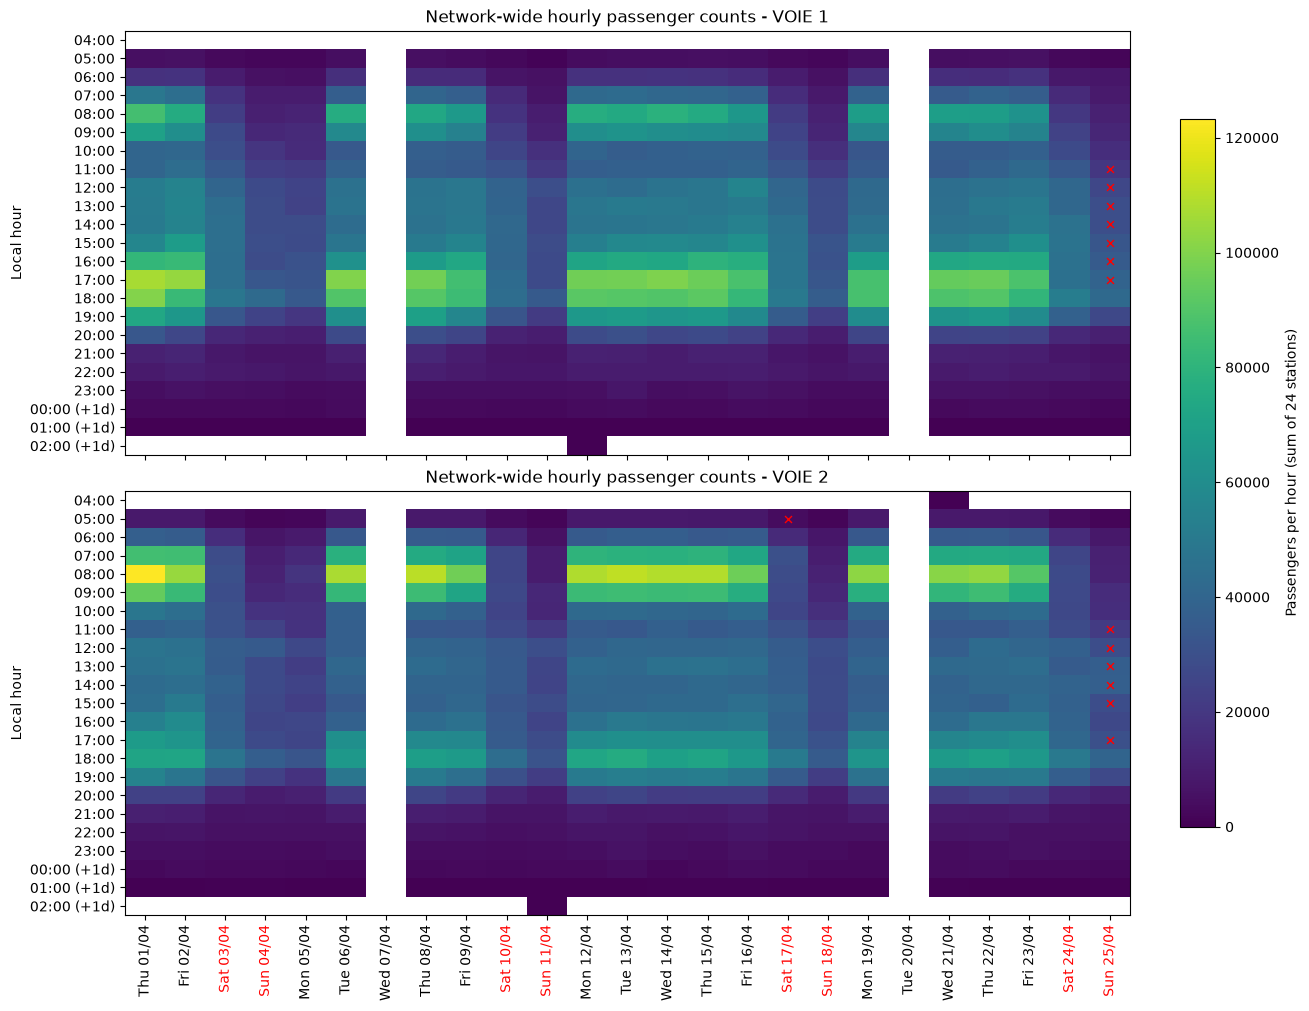

In [7]:
def network_hourly(hourly, regular):
    # Network-wide totals per (op_date, voie, hour) + number of stations recorded + completeness flag
    df = pd.DataFrame({"count": hourly.to_numpy(),
                       "observed": hourly.notna().to_numpy(),
                       "expected": expected_mask(hourly, regular)}, index=hourly.index)
    df["missing_expected"] = df["expected"] & ~df["observed"]
    g = df.groupby(level=["op_date", "voie", "hour"], sort=False)
    out = pd.DataFrame({"total": g["count"].sum(min_count=1),
                        "n_stations": g["observed"].sum(),
                        "n_missing_expected": g["missing_expected"].sum()})
    out["complete"] = out["n_missing_expected"] == 0
    return out


def plot_network_heatmaps(net, dates, hours):
    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("white")
    vmax = net["total"].max()
    fig, axes = plt.subplots(len(VOIES), 1, figsize=(13, 10), sharex=True, constrained_layout=True)
    for ax, voie in zip(axes, VOIES):
        sub = net.xs(voie, level="voie")
        mat = sub["total"].unstack("op_date").reindex(index=hours, columns=dates)
        inc = (~sub["complete"]).unstack("op_date").reindex(index=hours, columns=dates).fillna(False)
        im = ax.imshow(np.ma.masked_invalid(mat.to_numpy(dtype=float)), aspect="auto", cmap=cmap,
                       vmin=0, vmax=vmax, interpolation="nearest")
        yy, xx = np.nonzero(inc.to_numpy(dtype=bool) & mat.notna().to_numpy())
        ax.scatter(xx, yy, marker="x", color="red", s=25, lw=1)
        set_hour_axis(ax, hours, axis="y")
        ax.set_ylabel("Local hour")
        ax.set_title(f"Network-wide hourly passenger counts - VOIE {voie}")
        ax.grid(False)
    ax.set_xticks(range(len(dates)), [f"{d:%a %d/%m}" for d in dates], rotation=90)
    for lbl, d in zip(ax.get_xticklabels(), dates):
        if d.dayofweek >= 5:
            lbl.set_color("red")
    fig.colorbar(im, ax=axes, label="Passengers per hour (sum of 24 stations)", shrink=0.8)
    return fig


net_train = network_hourly(hourly_train, regular_train)
fig = plot_network_heatmaps(net_train, TRAIN_DATES, HOURS)
save_fig(fig, "1_1_network_heatmaps")
plt.show()

In [8]:
# Mean network profile per direction and day type (complete cells only)
tbl = net_train[net_train["complete"]].reset_index()
tbl["day_type"] = day_type(tbl["op_date"])
mean_net = tbl.groupby(["voie", "day_type", "hour"])["total"].mean().unstack("hour").reindex(columns=HOURS)
print(mean_net.rename(columns=hour_label).round(0).to_string())
print("\nPeak hour of the mean profile:")
print(mean_net.idxmax(axis=1).map(hour_label))

hour           04:00   05:00    06:00    07:00    08:00    09:00    10:00    11:00    12:00    13:00    14:00    15:00    16:00    17:00    18:00    19:00    20:00    21:00   22:00   23:00  00:00 (+1d)  01:00 (+1d)  02:00 (+1d)
voie day_type                                                                                                                                                                                                                      
1    weekday     NaN  4643.0  16022.0  38102.0  68795.0  56726.0  35812.0  37052.0  46277.0  47380.0  47599.0  54080.0  71235.0  91118.0  85143.0  61219.0  26006.0  10826.0  9064.0  5207.0       3352.0         18.0         33.0
     weekend     NaN  2280.0   7144.0  12026.0  15611.0  18648.0  22380.0  28052.0  35201.0  35821.0  37536.0  38637.0  37900.0  39384.0  43782.0  29516.0  11948.0   6936.0  7936.0  4702.0       2840.0         24.0          NaN
2    weekday    22.0  7876.0  33453.0  73447.0  99452.0  77706.0  40002.0  34505.0  3979

**Observations**
- Weekdays show two daily peaks in both directions: a morning peak at 08:00–09:00 and an afternoon peak at 17:00–18:00; weekends have a single, flatter plateau from late morning to about 18:00, peaking around 18:00.
- The directions are mirror images: VOIE 2 has the stronger morning peak (≈ 99 000 pass./h at 08:00 on average weekdays vs ≈ 69 000 for VOIE 1), while VOIE 1 has the stronger afternoon peak (≈ 91 000 at 17:00 vs ≈ 67 000 at 18:00 for VOIE 2). The VOIE 2 evening peak is also about one hour later (18:00) than the VOIE 1 one (17:00).
- Demand falls sharply after 19:00–20:00 in both directions; 00:00–02:00 (+1d) and 04:00–05:00 carry very little demand.
- Exceptions: Monday 5 April looks like a Sunday (no commuting peaks); 7 and 20 April have no records at all (blank columns); Sunday 25 April is incomplete (station 12 missing 11:00–17:00, `×`); 01:00 (+1d) and 02:00 (+1d) are recorded only by a few stations, so these rows are sparse by construction.
- The first two days (1–2 April) have the highest peaks of the period; the level is otherwise stable from week to week.

**Possible explanations:** the opposite peak directions suggest that VOIE 2 points towards the main employment/activity area (morning inbound) and VOIE 1 away from it (evening return). 5 April 2021 was Easter Monday (public holiday). The early drop after 19:00 is consistent with an evening curfew that was in force in spring 2021, and the higher 1–2 April levels could be linked to the change of sanitary restrictions/school holidays starting in early April.

## 1.2 Compare daily totals and weekly patterns

Daily total = sum of the network-wide hourly counts over all recorded hours of the operating day, per direction.
Incomplete days are shown with hollow markers and left out of the day-of-week distributions.

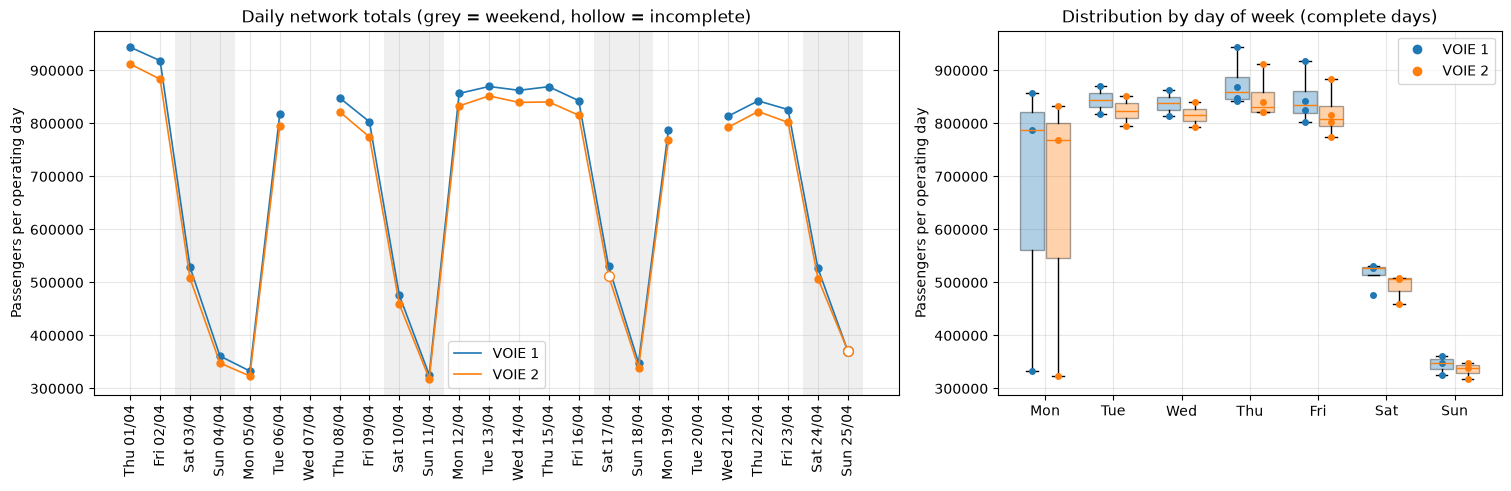

In [ ]:
def daily_totals(net):
    g = net.groupby(level=["op_date", "voie"])
    out = pd.DataFrame({"total": g["total"].sum(min_count=1),
                        "n_missing_expected": g["n_missing_expected"].sum()})
    out["complete"] = out["n_missing_expected"] == 0
    dates = out.index.get_level_values("op_date")
    out["weekday"] = dates.dayofweek
    out["day_type"] = day_type(dates)
    return out


daily_train = daily_totals(net_train)
daily_wide = daily_train["total"].unstack("voie")
complete_wide = daily_train["complete"].unstack("voie")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.6, 1]},
                               constrained_layout=True)

# a) daily series on the full calendar (gaps for dates without records)
for voie in VOIES:
    s = daily_wide[voie].reindex(TRAIN_DATES)
    ok = complete_wide[voie].reindex(TRAIN_DATES).fillna(False).astype(bool)
    ax1.plot(s.index, s, color=VOIE_COLORS[voie], lw=1.2, label=f"VOIE {voie}")
    ax1.plot(s.index[ok], s[ok], "o", color=VOIE_COLORS[voie], ms=5)
    ax1.plot(s.index[~ok], s[~ok], "o", mfc="white", mec=VOIE_COLORS[voie], ms=7)
for d in dates_of_type(TRAIN_DATES, "weekend"):
    ax1.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color="grey", alpha=0.12, lw=0)
ax1.set_xticks(TRAIN_DATES, [f"{d:%a %d/%m}" for d in TRAIN_DATES], rotation=90)
ax1.set_ylabel("Passengers per operating day")
ax1.set_title("Daily network totals (grey = weekend, hollow = incomplete)")
ax1.legend()

# b) distribution by day of week, complete days only
ok_days = daily_train[daily_train["complete"]].reset_index()
width = 0.38
for k, voie in enumerate(VOIES):
    data = [ok_days.loc[(ok_days.voie == voie) & (ok_days.weekday == wd), "total"].to_numpy() for wd in range(7)]
    pos = np.arange(7) + (k - 0.5) * width
    bp = ax2.boxplot(data, positions=pos, widths=width * 0.9, patch_artist=True, showfliers=False)
    for patch in bp["boxes"]:
        patch.set_facecolor(VOIE_COLORS[voie])
        patch.set_alpha(0.35)
    for p, vals in zip(pos, data):
        ax2.plot(np.full(len(vals), p), vals, "o", color=VOIE_COLORS[voie], ms=4)
ax2.set_xticks(range(7), WEEKDAY_NAMES)
ax2.set_ylabel("Passengers per operating day")
ax2.set_title("Distribution by day of week (complete days)")
ax2.legend(handles=[Line2D([], [], color=VOIE_COLORS[v], marker="o", lw=0, label=f"VOIE {v}") for v in VOIES])
save_fig(fig, "1_2_daily_totals")
plt.show()

In [10]:
print("Complete days per weekday and direction:")
print(ok_days.groupby(["voie", "weekday"]).size().unstack("weekday").rename(columns=dict(enumerate(WEEKDAY_NAMES))))

summary_daytype = ok_days.groupby(["day_type", "voie"])["total"].agg(["count", "mean", "std", "min", "max"]).round(0)
print("\nDaily totals by day type and direction (complete days):")
print(summary_daytype)
print("\nWeekend / weekday mean ratio:",
      (summary_daytype["mean"]["weekend"] / summary_daytype["mean"]["weekday"]).round(3).to_dict())

ratio = (daily_wide[1] / daily_wide[2])[complete_wide.all(axis=1)]
print("\nRatio VOIE 1 / VOIE 2 of daily totals (days complete in both directions):")
print(ratio.groupby(day_type(ratio.index)).describe().round(3))

print("\nIncomplete days:")
print(daily_train[~daily_train["complete"] & daily_train["total"].notna()][["total", "n_missing_expected"]])

Complete days per weekday and direction:
weekday  Mon  Tue  Wed  Thu  Fri  Sat  Sun
voie                                      
1          3    2    2    4    4    4    3
2          3    2    2    4    4    3    3

Daily totals by day type and direction (complete days):
               count      mean       std       min       max
day_type voie                                               
weekday  1        15  815682.0  139695.0  332880.0  943706.0
         2        15  791846.0  135067.0  323553.0  911922.0
weekend  1         7  442344.0   93500.0  325508.0  530275.0
         2         6  413303.0   87774.0  318764.0  507720.0

Weekend / weekday mean ratio: {1: 0.542, 2: 0.522}

Ratio VOIE 1 / VOIE 2 of daily totals (days complete in both directions):
         count   mean    std    min    25%    50%    75%    max
weekday   15.0  1.030  0.005  1.021  1.027  1.029  1.034  1.039
weekend    6.0  1.034  0.008  1.021  1.030  1.037  1.038  1.041

Incomplete days:
                    total  

**Observations**
- Complete weekdays carry ≈ 815 000 (VOIE 1) and ≈ 790 000 (VOIE 2) passengers per day; weekends ≈ 440 000 / 415 000, so about 52–54 % of a weekday. Saturdays (≈ 475 000–530 000) are clearly higher than Sundays (≈ 320 000–360 000).
- Tuesday to Friday are very similar; Thursday and Friday 1–2 April are the highest days. The large spread on Mondays is entirely due to Easter Monday (≈ 330 000, Sunday level).
- VOIE 1 is systematically ≈ 3 % higher than VOIE 2 (daily ratio 1.02–1.04 on every complete day, weekdays and weekends). So over a whole day the directions almost balance, even though their hourly profiles are very different (1.1): the asymmetry is in timing, not in volume.
- Incomplete days: 25 April (both directions, station 12) and 17 April (VOIE 2, one station-hour) : their totals are under-estimates and are not used in the distributions.

**Possible explanations:** near-balanced daily totals are expected for round trips (people who leave in one direction come back in the other). The small but constant excess of VOIE 1 could come from the counting equipment, or from passengers using another mode for one leg of the trip; the data do not allow distinguishing these.

## 1.3 Hourly profiles across stations (VOIE 1)

Representative profile of station $s$: $\bar c_{s,h} = \frac{1}{|D_{s,h}|}\sum_{d\in D_{s,h}} c_{d,s,h}$, the mean over
the training dates $D_{s,h}$ on which interval $h$ was recorded (missing intervals are skipped, not counted as 0).

Normalization: each profile is divided by its own maximum, $\tilde c_{s,h} = \bar c_{s,h} / \max_{h'} \bar c_{s,h'}$,
so every profile peaks at 1. This removes the demand level of the station and keeps only the shape of the profile
(peak timing and relative size of the morning and evening peaks).

Number of training dates behind each hourly mean (min / max over stations):
hour  04:00  05:00  06:00  07:00  08:00  09:00  10:00  11:00  12:00  13:00  14:00  15:00  16:00  17:00  18:00  19:00  \
min       0     23     23     23     23     23     23     22     22     22     22     22     22     22     23     23   
max       0     23     23     23     23     23     23     23     23     23     23     23     23     23     23     23   

hour  20:00  21:00  22:00  23:00  00:00 (+1d)  01:00 (+1d)  02:00 (+1d)  
min      23     23     23     23           23            0            0  
max      23     23     23     23           23           23            1  


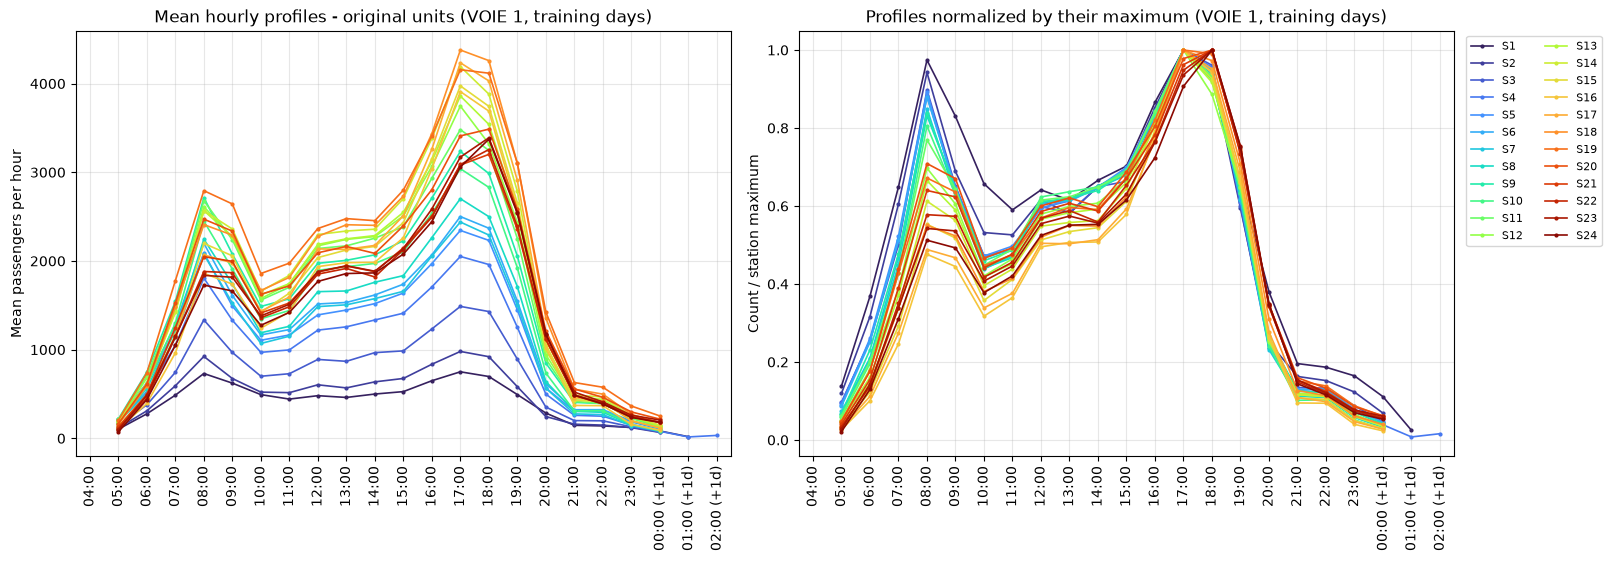

In [11]:
def mean_profiles(hourly, hours, by="station"):
    # Mean count per hour (NaN skipped) for each group + number of dates used per hour
    g = hourly.groupby(level=[by, "hour"])
    return g.mean().unstack("hour").reindex(columns=hours), g.count().unstack("hour").reindex(columns=hours)


def normalize_by_max(profiles):
    return profiles.div(profiles.max(axis=1), axis=0)


def peak_summary(profiles, hours, split_hour=12):
    # Morning (before split_hour) and afternoon peaks of each profile (one row per profile)
    am = [h for h in hours if opday_position(h) < opday_position(split_hour)]
    pm = [h for h in hours if opday_position(h) >= opday_position(split_hour)]
    out = pd.DataFrame(index=profiles.index)
    out["daily_sum"] = profiles.sum(axis=1, min_count=1)
    out["am_peak_hour"] = profiles[am].idxmax(axis=1).map(hour_label)
    out["am_peak"] = profiles[am].max(axis=1)
    out["pm_peak_hour"] = profiles[pm].idxmax(axis=1).map(hour_label)
    out["pm_peak"] = profiles[pm].max(axis=1)
    out["am_pm_ratio"] = out["am_peak"] / out["pm_peak"]
    return out


profiles_v1, profiles_v1_n = mean_profiles(select(hourly_train, voies=[1]), HOURS)
profiles_v1_norm = normalize_by_max(profiles_v1)

print("Number of training dates behind each hourly mean (min / max over stations):")
print(pd.DataFrame({"min": profiles_v1_n.min(), "max": profiles_v1_n.max()}).T.rename(columns=hour_label))

station_colors = dict(zip(STATIONS, plt.cm.turbo(np.linspace(0.02, 0.98, len(STATIONS)))))
x = np.arange(len(HOURS))
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), constrained_layout=True)
for ax, prof, title, ylabel in [
    (axes[0], profiles_v1, "Mean hourly profiles - original units", "Mean passengers per hour"),
    (axes[1], profiles_v1_norm, "Profiles normalized by their maximum", "Count / station maximum"),
]:
    for s in STATIONS:
        ax.plot(x, prof.loc[s], marker=".", ms=4, lw=1.2, color=station_colors[s], label=f"S{s}")
    set_hour_axis(ax, HOURS)
    ax.set_title(f"{title} (VOIE 1, training days)")
    ax.set_ylabel(ylabel)
axes[1].legend(ncol=2, fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
save_fig(fig, "1_3_station_profiles")
plt.show()

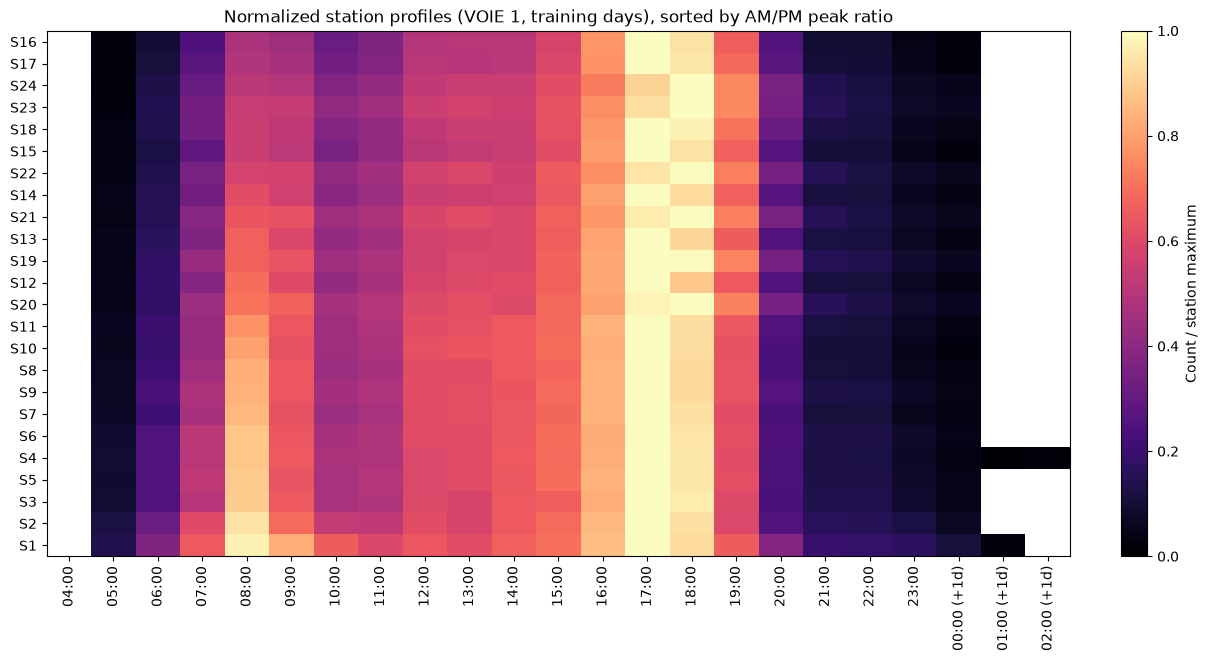

         daily_sum am_peak_hour  am_peak pm_peak_hour  pm_peak  am_pm_ratio
station                                                                    
16        31137.13        08:00  1861.04        17:00  3910.09         0.48
17        34586.83        08:00  2068.13        17:00  4234.91         0.49
24        29097.96        08:00  1728.22        18:00  3373.91         0.51
23        30393.26        08:00  1838.04        18:00  3388.65         0.54
18        38261.48        08:00  2410.13        17:00  4378.78         0.55
15        33596.61        08:00  2197.91        17:00  3974.09         0.55
22        29652.22        08:00  1881.35        18:00  3256.57         0.58
14        37043.04        08:00  2566.57        17:00  4191.65         0.61
21        30285.78        08:00  2048.74        18:00  3202.00         0.64
13        35070.43        08:00  2568.00        17:00  3860.17         0.67
19        40119.09        08:00  2792.70        17:00  4156.74         0.67
12        34

In [12]:
# Normalized profiles as a heatmap, stations sorted by their morning/afternoon peak ratio
peaks_v1 = peak_summary(profiles_v1, HOURS)
order = peaks_v1.sort_values("am_pm_ratio").index

cmap = plt.get_cmap("magma").copy()
cmap.set_bad("white")
fig, ax = plt.subplots(figsize=(12, 6.5), constrained_layout=True)
im = ax.imshow(np.ma.masked_invalid(profiles_v1_norm.loc[order].to_numpy(dtype=float)),
               aspect="auto", cmap=cmap, vmin=0, vmax=1, interpolation="nearest")
set_hour_axis(ax, HOURS)
ax.set_yticks(range(len(order)), [f"S{s}" for s in order])
ax.set_title("Normalized station profiles (VOIE 1, training days), sorted by AM/PM peak ratio")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Count / station maximum")
save_fig(fig, "1_3_station_profiles_norm_heatmap")
plt.show()

print(peaks_v1.loc[order].round(2).to_string())

**Observations**
- Original units: demand levels differ by a factor of ≈ 5 between stations (daily sum ≈ 8 500 at S1 vs ≈ 40 000 at S19); stations 1-3 are clearly the smallest, stations 14–19 the largest. Differences between stations are largest at the afternoon peak.
- Normalized: once the level is removed, all stations share the same timing — morning peak at 08:00, afternoon peak at 17:00 or 18:00, midday trough at 10:00–11:00, steep drop at 20:00. This common shape was hidden by the level differences in the original plot.
- What normalization reveals as a real difference is the relative strength of the two peaks (AM/PM ratio): ≈ 0.8–1.0 for stations 1–9 (balanced peaks), ≈ 0.5–0.6 for stations 15–18 and 22–24 (afternoon peak about twice the morning one); intermediate stations (10–14, 19–21) lie in between. The ratio varies almost monotonically with the station number.
- Differences that disappear with normalization: the absolute level of each station and the absolute gap between stations at the peaks. Hours 01:00–02:00 (+1d) are based on 1–2 dates only.

**Possible explanations:** if station numbers follow the order along the line, VOIE 1 passengers boarding at the low-numbered stations travel in both peaks (residential and activity uses mixed), while at the high-numbered stations VOIE 1 boardings are mostly an evening return trip.

## 1.4 Compare weekday and weekend station profiles (stations 1, 7, 16, 19; VOIE 1)

For each station and day type: mean over training dates at each hour; band = mean ± 1 standard deviation across dates.

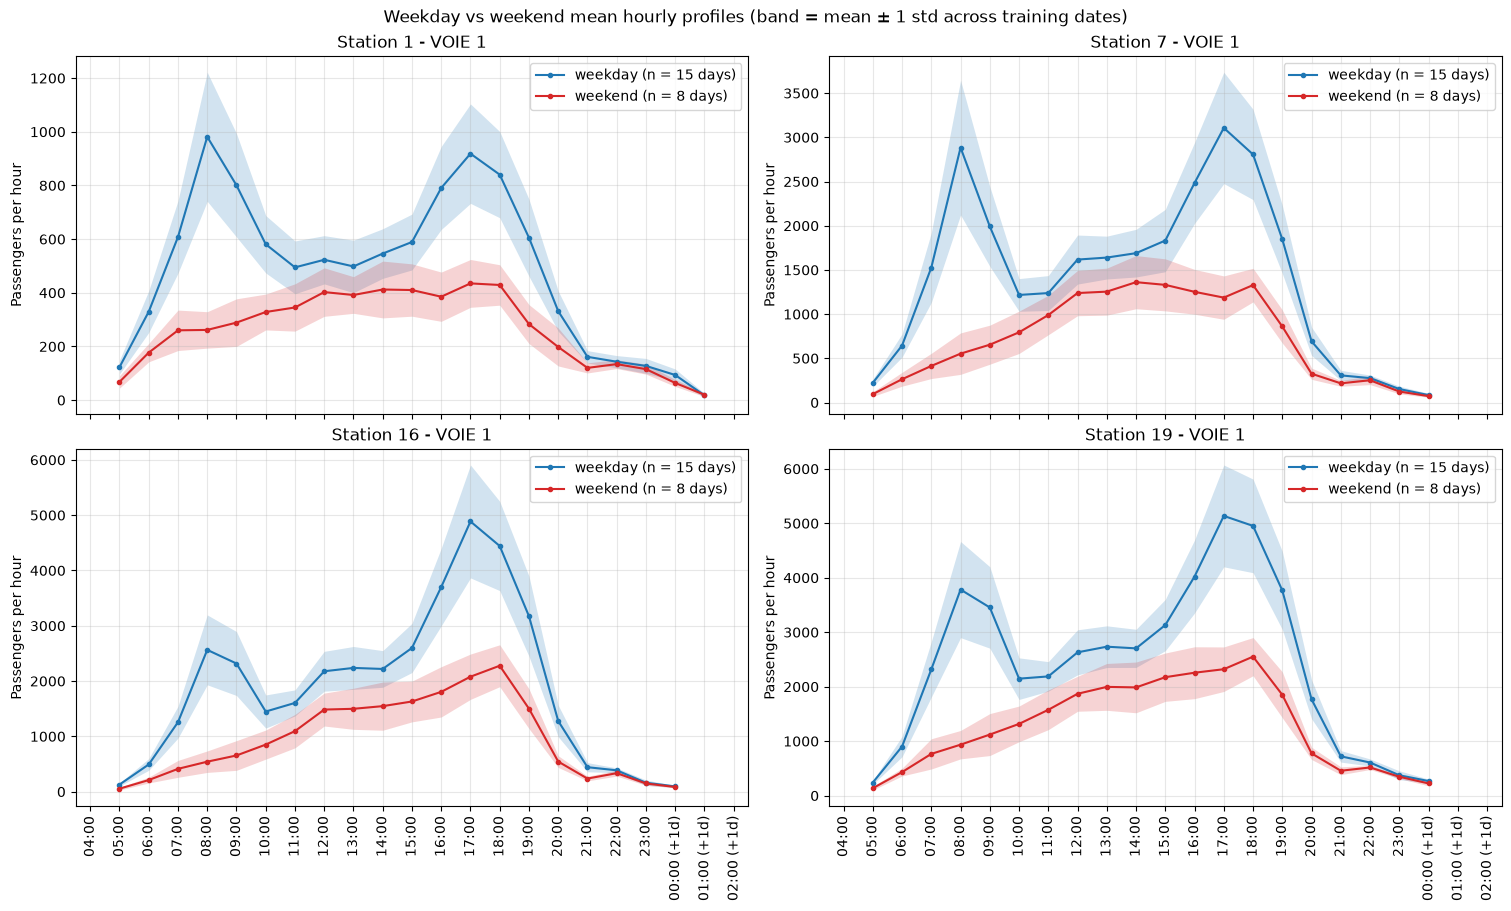

                  daily_sum am_peak_hour  am_peak pm_peak_hour  pm_peak  am_pm_ratio  mean_rel_std
station day_type                                                                                  
1       weekday    10104.73        08:00   981.40        17:00   918.53         1.07          0.21
        weekend     5530.62        11:00   345.25        17:00   435.00         0.79          0.24
7       weekday    28262.53        08:00  2884.13        17:00  3107.00         0.93          0.19
        weekend    14568.75        11:00   989.75        14:00  1361.62         0.73          0.24
16      weekday    37614.73        08:00  2564.40        17:00  4886.60         0.52          0.20
        weekend    18991.62        11:00  1094.88        18:00  2277.50         0.48          0.26
19      weekday    47855.73        08:00  3783.20        17:00  5135.80         0.74          0.17
        weekend    25612.88        11:00  1575.75        18:00  2551.88         0.62          0.21


In [13]:
FOCUS_STATIONS = [1, 7, 16, 19]


def profile_stats(hourly, hours):
    # Mean, std (across dates, ddof=1) and number of dates per hour
    g = hourly.groupby(level="hour")
    return pd.DataFrame({"mean": g.mean(), "std": g.std(ddof=1), "n": g.count()}).reindex(hours)


def plot_band(ax, stats, label, color):
    # Mean line + mean +/- 1 std band; NaN hours leave gaps
    x = np.arange(len(stats))
    ax.plot(x, stats["mean"], marker="o", ms=3, color=color, label=label)
    ax.fill_between(x, stats["mean"] - stats["std"], stats["mean"] + stats["std"], color=color, alpha=0.2, lw=0)


fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True, constrained_layout=True)
rows = []
for ax, s in zip(axes.ravel(), FOCUS_STATIONS):
    for kind in ["weekday", "weekend"]:
        st = profile_stats(select(hourly_train, dates=dates_of_type(TRAIN_DATES, kind), stations=[s], voies=[1]), HOURS)
        plot_band(ax, st, f"{kind} (n = {st['n'].max()} days)", DAYTYPE_COLORS[kind])
        pk = peak_summary(st[["mean"]].T, HOURS).iloc[0]
        rows.append({"station": s, "day_type": kind, **pk.to_dict(),
                     "mean_rel_std": (st["std"] / st["mean"]).mean()})
    set_hour_axis(ax, HOURS)
    ax.set_title(f"Station {s} - VOIE 1")
    ax.set_ylabel("Passengers per hour")
    ax.legend()
fig.suptitle("Weekday vs weekend mean hourly profiles (band = mean ± 1 std across training dates)")
save_fig(fig, "1_4_weekday_weekend_profiles")
plt.show()

print(pd.DataFrame(rows).set_index(["station", "day_type"]).round(2).to_string())

**Observations**
- Weekdays: two peaks at 08:00 and 17:00 at all four stations. Weekends: no morning peak, demand rises gradually to a broad plateau between 12:00 and 18:00 (peak hour 14:00–18:00).
- Weekend demand is about half the weekday one (daily sum ratio ≈ 0.51–0.55); the difference is concentrated in the peaks, while late-evening (after 21:00) counts are almost identical.
- Relative peak strength differs by station: on weekdays S1 has a slightly stronger morning peak (AM/PM ≈ 1.07), S7 has balanced peaks (0.93), S19 (0.74) and S16 (0.52) are afternoon-dominated.
- Variability: the weekday bands are widest at the peaks (relative std ≈ 0.17–0.21), partly inflated by Easter Monday; weekend bands are narrower in absolute value but relatively larger (≈ 0.21–0.26), reflecting Saturday/Sunday differences.

**Possible explanation:** weekday peaks are driven by commuting (work/school); weekend trips are more discretionary (shopping, leisure), spread over the day.

## 1.5 Examine directional differences at stations (weekdays)

Same statistics as in 1.4, comparing VOIE 1 and VOIE 2 on the training weekdays.

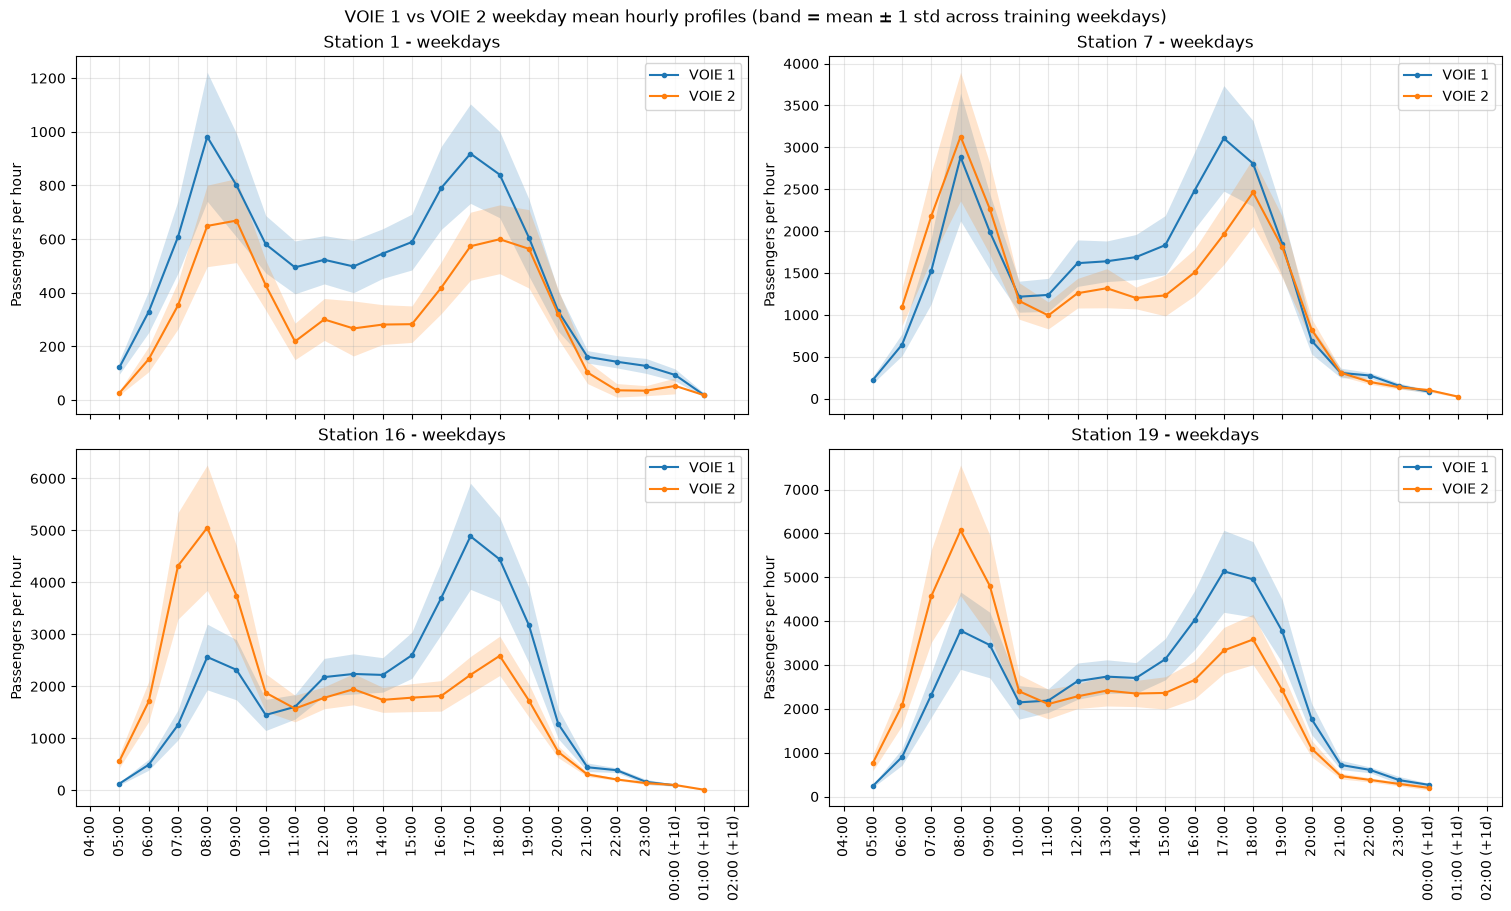

In [14]:
TRAIN_WEEKDAYS = dates_of_type(TRAIN_DATES, "weekday")

fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True, constrained_layout=True)
dir_stats = {}
for ax, s in zip(axes.ravel(), FOCUS_STATIONS):
    for voie in VOIES:
        st = profile_stats(select(hourly_train, dates=TRAIN_WEEKDAYS, stations=[s], voies=[voie]), HOURS)
        dir_stats[(s, voie)] = st
        plot_band(ax, st, f"VOIE {voie}", VOIE_COLORS[voie])
    set_hour_axis(ax, HOURS)
    ax.set_title(f"Station {s} - weekdays")
    ax.set_ylabel("Passengers per hour")
    ax.legend()
fig.suptitle("VOIE 1 vs VOIE 2 weekday mean hourly profiles (band = mean ± 1 std across training weekdays)")
save_fig(fig, "1_5_directional_profiles")
plt.show()

         daily V1  daily V2  share V1 (day)  early 05-07  AM peak 07-09  midday 09-16  PM peak 16-19  evening 19-01
station                                                                                                            
1        10104.73   6351.71            0.61         0.72           0.61          0.62           0.62           0.57
7        28262.53  25175.73            0.53         0.44           0.45          0.54           0.59           0.50
16       37614.73  35931.27            0.51         0.21           0.29          0.50           0.66           0.63
19       47855.73  46635.73            0.51         0.29           0.36          0.50           0.60           0.61


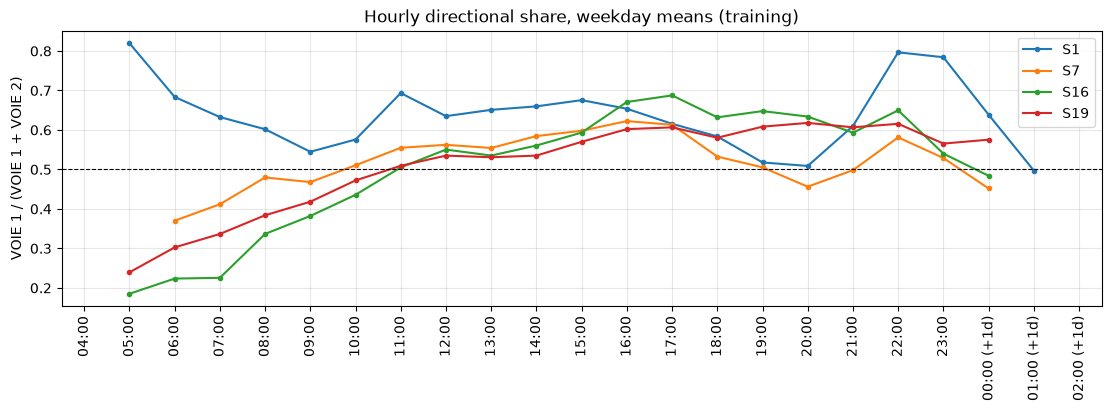

In [15]:
# Share of VOIE 1 in the two-direction total of the weekday mean profile, by period of the day (0.5 = symmetric)
PERIODS = {"early 05-07": [5, 6], "AM peak 07-09": [7, 8], "midday 09-16": list(range(9, 16)),
           "PM peak 16-19": [16, 17, 18], "evening 19-01": [19, 20, 21, 22, 23, 0]}
rows = []
for s in FOCUS_STATIONS:
    m1, m2 = dir_stats[(s, 1)]["mean"], dir_stats[(s, 2)]["mean"]
    row = {"station": s, "daily V1": m1.sum(), "daily V2": m2.sum(), "share V1 (day)": m1.sum() / (m1.sum() + m2.sum())}
    row.update({name: m1[hs].sum() / (m1[hs].sum() + m2[hs].sum()) for name, hs in PERIODS.items()})
    rows.append(row)
print(pd.DataFrame(rows).set_index("station").round(2).to_string())

fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
for s in FOCUS_STATIONS:
    m1, m2 = dir_stats[(s, 1)]["mean"], dir_stats[(s, 2)]["mean"]
    ax.plot(np.arange(len(HOURS)), (m1 / (m1 + m2)).to_numpy(), marker="o", ms=3, label=f"S{s}")
ax.axhline(0.5, color="k", lw=0.8, ls="--")
set_hour_axis(ax, HOURS)
ax.set_ylabel("VOIE 1 / (VOIE 1 + VOIE 2)")
ax.set_title("Hourly directional share, weekday means (training)")
ax.legend()
save_fig(fig, "1_5_directional_share")
plt.show()

**Observations**
- **Station 1**: VOIE 1 dominates at almost every hour (≈ 61 % of the daily total), with both peaks higher in VOIE 1.
- **Station 7**: nearly symmetric (VOIE 1 share ≈ 53 %): VOIE 2 slightly higher in the morning (45 % VOIE 1 at 07–09), VOIE 1 higher in the afternoon (59 % at 16–19).
- **Stations 16 and 19**: daily totals are balanced (≈ 51 % VOIE 1) but the asymmetry is strong and reverses during the day: VOIE 2 dominates the morning (VOIE 1 share only 21–36 % before 09:00; VOIE 2 peak ≈ 5 000–6 000 pass./h at 08:00), VOIE 1 dominates the afternoon (60–66 %).
- Midday (10:00–15:00) is the most symmetric period at all stations; variability bands of the dominant direction are the widest at its peak.
- So yes: directional asymmetry depends both on the station and on the time of day, and it grows with the station number.

**Possible explanation:** stations 16/19 behave like origins of tidal commuting (outbound towards the activity area in the morning on VOIE 2, return on VOIE 1 in the evening), while station 1 may be close to a terminus or a major activity zone where one direction is used more in both peaks. These are hypotheses: line geometry and land use are not in the data.